# E4 · Large swings (rung 2)
*Step 1 of network-spectral-predictor · pendulums on springs · actual = generated world, nominal = prediction*

When the swing is large enough that $\sin\theta \neq \theta$, which body lift keeps the model on track?

**Where we're at.** Step 1, moving from rung 1 (small swings) to rung 2 (sin θ matters).

**Where the system is after the last experiments.** In the linear world the model transfers across body counts and gate patterns (E2, E3).

**Where we want it.** A body map that holds at large swings, with the springs unchanged.

**How this set moves it.** Releases a path of 3 from 0.1 to 2 rad and compares three body lifts: none, + $\sin\theta$, + $\dot\theta\cos\theta$.

In [1]:
%config InlineBackend.figure_format = 'retina'
import sys
from pathlib import Path
import numpy as np
from IPython.display import display
STUDY = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(STUDY))
import figures as F
from nsp import config, graphs, viz, world as W
F.setup()
cfg = F.cfg("e4")
world = config.world_from(cfg)
p = cfg["e4"]

In [2]:
F.ledger("e4")

**Configuration ledger**

| Setting | Value | Meaning |
| --- | --- | --- |
| `world.omega0` | 2.0 | a lone pendulum's frequency (rad/s) |
| `world.kappa` | 1.0 | spring stiffness ÷ inertia (1/s²) |
| `world.dt` | 0.05 | sampling step (s) |
| `world.d` | 1 | position coordinates per body (1 = planar) |
| `run.seeds` | [0, 1, 2] | seeds run (kept low on purpose) |
| `graph` | path | how the springs are wired |
| `n` | 3 | number of bodies |
| `amplitudes` | [0.1, 0.5, 1.0, 2.0] | release angles (rad) |
| `lifts` | ['x', 'sin', 'sin+cos'] | body lifts compared |
| `train_trajectories` | 10 | trajectories per training configuration |
| `test_trajectories` | 10 | trajectories per test |
| `steps` | 200 | steps per trajectory |
| `substeps` | 50 | Verlet substeps per sample |
| `player_amplitude` | 2.0 | release angle shown in the player (rad) |

## The question

The world is no longer linear:

$$\ddot\theta_v = -\omega_0^2\sin\theta_v - \kappa\sum_{u\sim v} g_{uv}\,(\theta_v-\theta_u)$$

Expanding one step of length $\Delta t$ shows which features the body map needs:

$$\dot\theta(t+\Delta t) = \dot\theta + \Delta t\,\underbrace{\ddot\theta}_{-\omega_0^2\sin\theta\,-\,\kappa L\theta} + \tfrac{\Delta t^2}{2}\,\underbrace{\theta^{(3)}}_{-\omega_0^2\,\dot\theta\cos\theta\,-\,\kappa L\dot\theta} + \dots$$

($\theta^{(3)}$ is the third time derivative.) So the lift $\psi(x_v)$ needs $\sin\theta$ and its time derivative $\dot\theta\cos\theta$; the springs keep reading plain differences:

$$x_v(t+1) = W^\top\big[\,\psi(x_v(t))\,;\; s_v(t)\,\big], \qquad s_v(t) = \sum_{u\sim v} g_{uv}\big(x_v(t)-x_u(t)\big)$$

**Prediction.** Each added term cuts the deviation about 10× at large swings.
**Pass if** the best lift stays under 1% deviation at 10 s up to 2 rad.

In [3]:
runs = F.ensure_results("e4")

e4: 3 seeds loaded (code fb79448, run 2026-11-25T20:28:54+00:00)


## The world gets slower as it swings wider

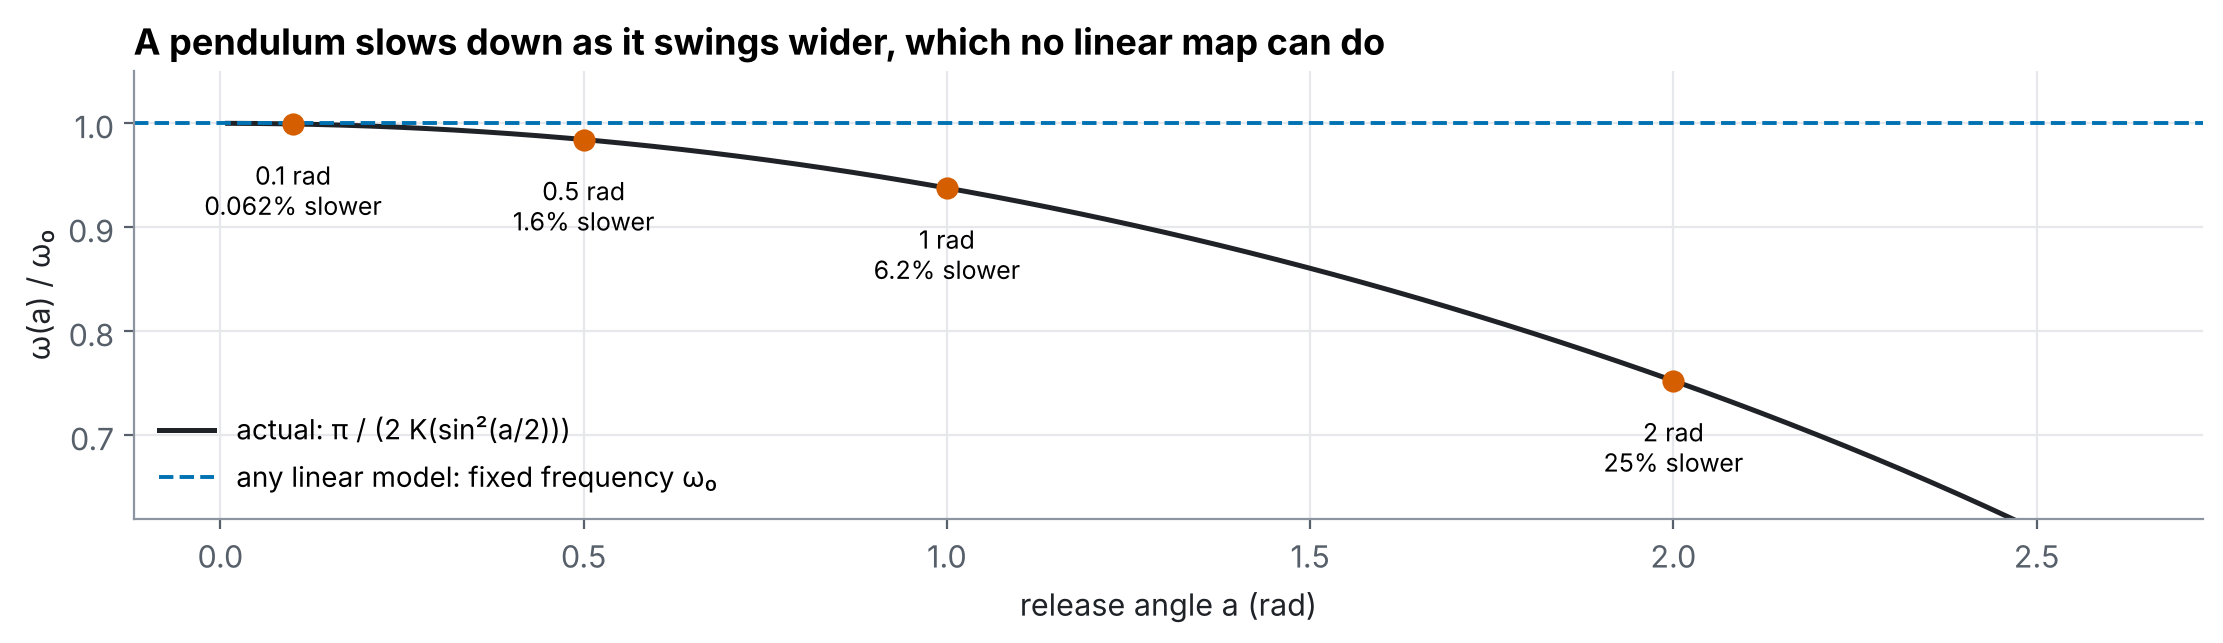

In [4]:
F.e4_frequency(world, p['amplitudes']);

## Nominal vs actual, released from up to 2 rad

Press **Play** to watch at real speed, or drag the slider. Actual bobs are filled, nominal bobs are hollow, and the whisker between them is the deviation, magnified (pick the factor) and coloured against the tolerance, like a CMM deviation plot. The trace underneath is the largest deviation over time. The first player uses no lift; the second uses the full lift.

In [5]:
a = runs[0]["arrays"]
tol = 0.01 * p["player_amplitude"]
display(viz.player(a["theta_act"], a["theta_nom_x"], graphs.path(3), dt=world.dt, tol=tol, height=330,
                   title="No lift: a linear model of a nonlinear pendulum",
                   subtitle="Tolerance: 1% of the 2 rad release angle."))
display(viz.player(a["theta_act"], a["theta_nom_sin+cos"], graphs.path(3), dt=world.dt, tol=tol, height=330,
                   title="Full lift: sin θ and its rate of change added to each body", subtitle="Same world, same springs."))

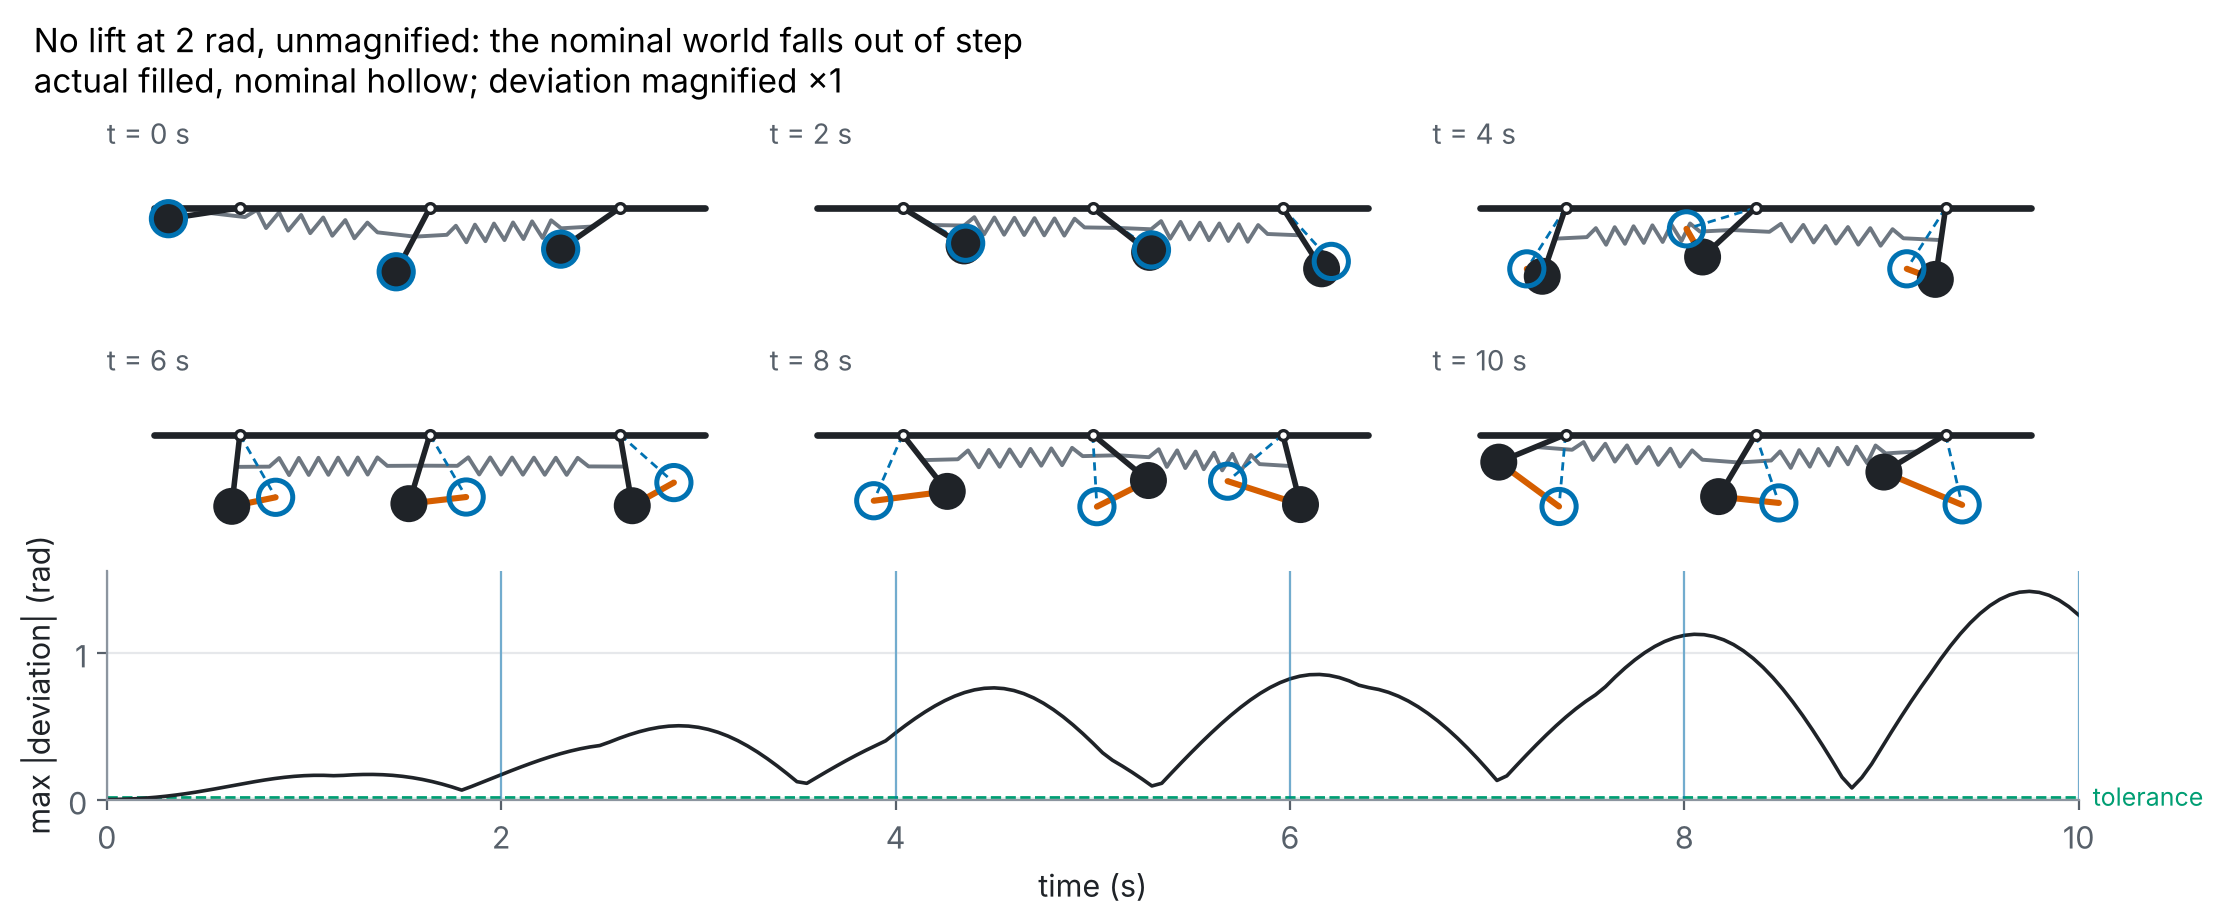

In [6]:
viz.film_strip(a["theta_act"], a["theta_nom_x"], graphs.path(3), dt=world.dt, tol=tol, amplify=1,
               title="No lift at 2 rad, unmagnified: the nominal world falls out of step");

## Deviation by lift and amplitude

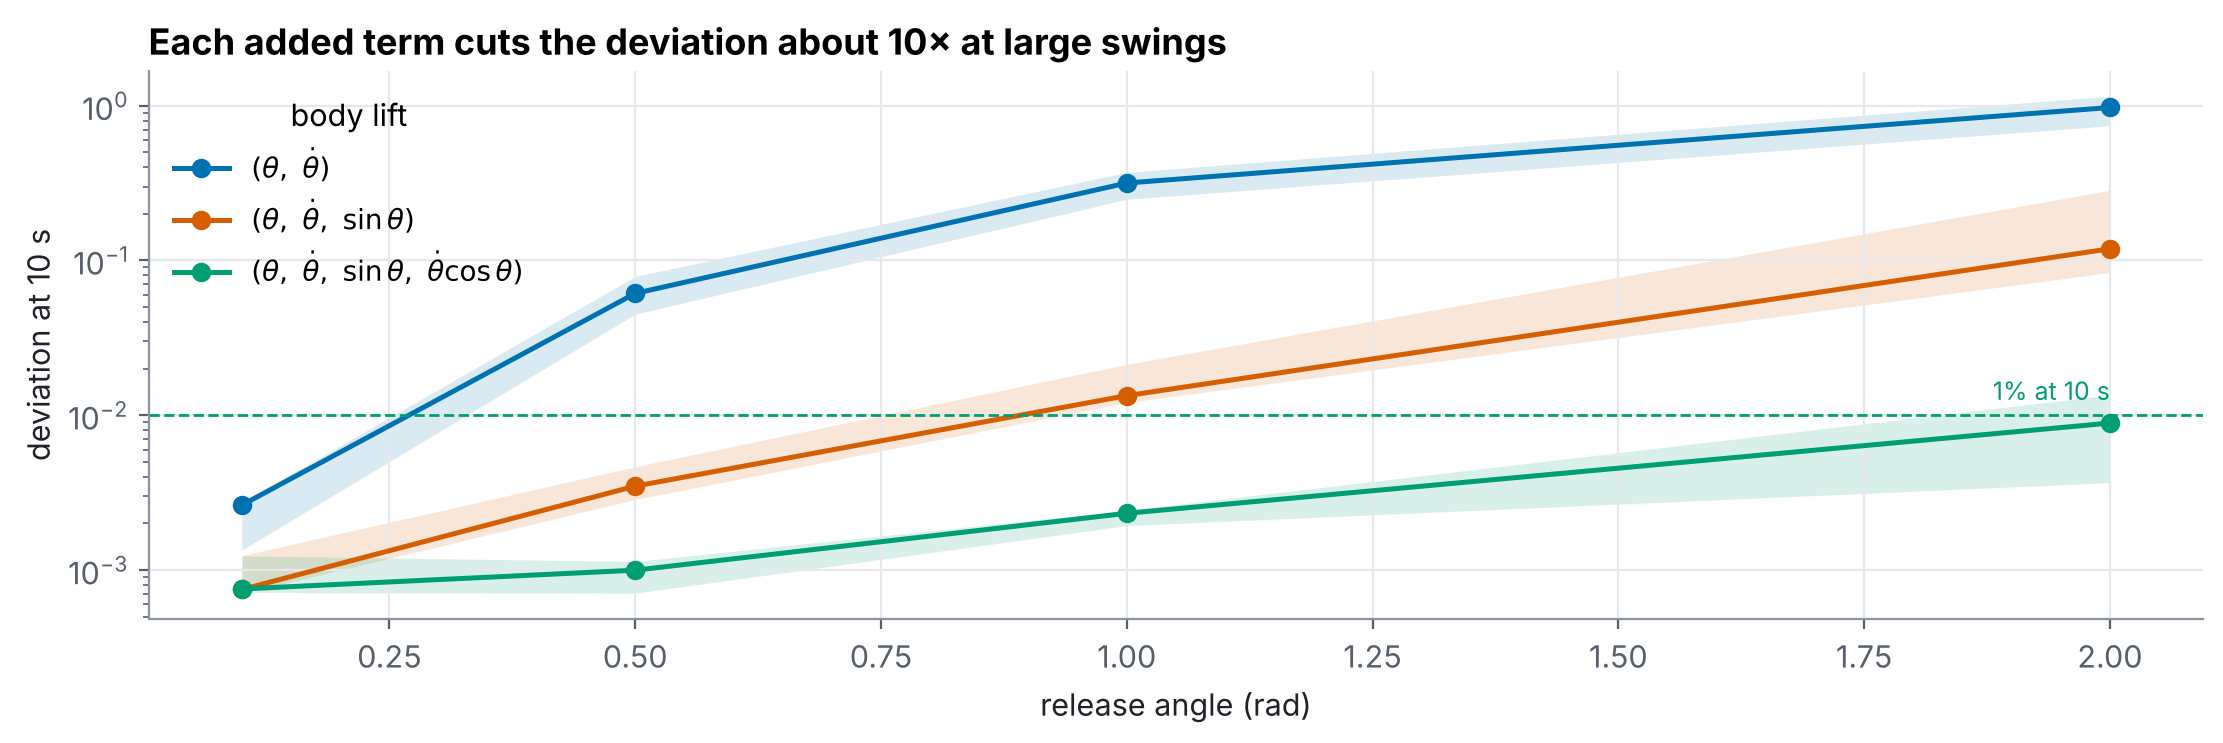

In [7]:
F.e4_errors(runs);

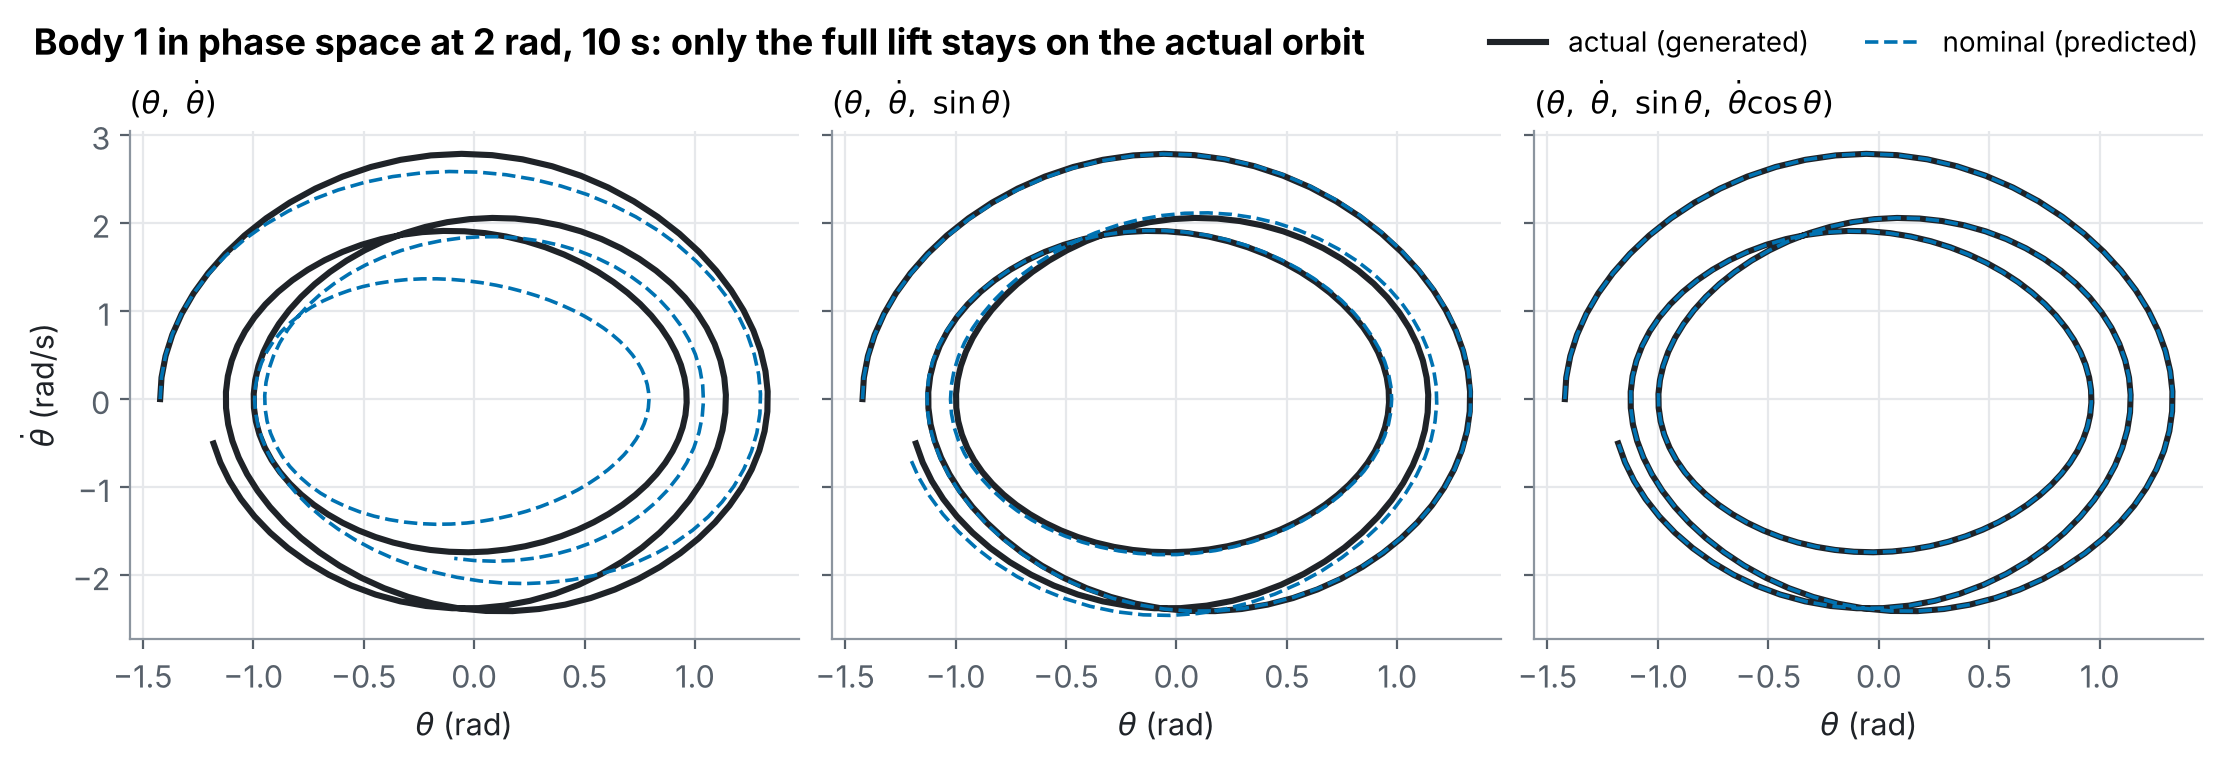

In [8]:
F.e4_phase(runs[0]);

In [9]:
from nsp.lifts import LABELS
r2 = lambda lift: [r["metrics"]["by_amplitude"]["2"]["lifts"][lift]["rollout"]["200"] for r in runs]
F.say(f"At 2 rad the deviation at 10 s is {F.spread(r2('x'))} with no lift, {F.spread(r2('sin'))} with sin θ and "
      f"{F.spread(r2('sin+cos'))} with $\\dot\\theta\\cos\\theta$ added. The full lift costs 4 body features instead of 2; the springs are "
      "untouched.")

> **Finding.** At 2 rad the deviation at 10 s is 0.955 (0.741 to 1.15) with no lift, 0.162 (0.0835 to 0.284) with sin θ and 0.00869 (0.00366 to 0.0135) with $\dot\theta\cos\theta$ added. The full lift costs 4 body features instead of 2; the springs are untouched.

## Inspection report

In [10]:
rows = []
for lift in p["lifts"]:
    for amp in ("1", "2"):
        v = float(np.mean([r["metrics"]["by_amplitude"][amp]["lifts"][lift]["rollout"]["200"] for r in runs]))
        rows.append({"characteristic": f"{LABELS[lift]} at {amp} rad: deviation at 10 s", "deviation": v, "tolerance": 0.01})
viz.inspection_report(rows, title="Large swings, means over seeds (the criterion applies to the best lift)")

**Large swings, means over seeds (the criterion applies to the best lift)**

| Characteristic | Nominal (predicted) | Actual (generated) | Deviation | Tolerance | Status |
| --- | --- | --- | --- | --- | --- |
| $(\theta,\ \dot\theta)$ at 1 rad: deviation at 10 s | — | — | 0.3117 | ±0.01 | ✗ **out** |
| $(\theta,\ \dot\theta)$ at 2 rad: deviation at 10 s | — | — | 0.9551 | ±0.01 | ✗ **out** |
| $(\theta,\ \dot\theta,\ \sin\theta)$ at 1 rad: deviation at 10 s | — | — | 0.01559 | ±0.01 | △ **near** |
| $(\theta,\ \dot\theta,\ \sin\theta)$ at 2 rad: deviation at 10 s | — | — | 0.1621 | ±0.01 | ✗ **out** |
| $(\theta,\ \dot\theta,\ \sin\theta,\ \dot\theta\cos\theta)$ at 1 rad: deviation at 10 s | — | — | 0.002228 | ±0.01 | ✓ **in** |
| $(\theta,\ \dot\theta,\ \sin\theta,\ \dot\theta\cos\theta)$ at 2 rad: deviation at 10 s | — | — | 0.008692 | ±0.01 | ✓ **in** |

## Log

In [11]:
F.log(runs)

| Seed | Code version | Run at (UTC) | Python | NumPy | SciPy |
| --- | --- | --- | --- | --- | --- |
| 0 | `fb79448` | 2026-11-25T20:28:54+00:00 | 3.13.18 | 2.5.3 | 1.18.1 |
| 1 | `fb79448` | 2026-11-25T20:28:54+00:00 | 3.13.18 | 2.5.3 | 1.18.1 |
| 2 | `fb79448` | 2026-11-25T20:28:55+00:00 | 3.13.18 | 2.5.3 | 1.18.1 |